# E-Commerce Customer Sales Analysis

## Project Objective

The objective of this project is to analyze customer purchasing behavior using the Online Retail dataset. The project includes data cleaning, exploratory data analysis (EDA), RFM analysis, customer segmentation, and exporting cleaned datasets for Power BI dashboard development.

In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Load Dataset

In this step, we load the Online Retail dataset into a Pandas DataFrame for further analysis.

In [3]:
# Load the Online Retail dataset

df = pd.read_csv(
    "../Datasets/raw_sales_data.csv",
    encoding="ISO-8859-1"
)

print("Dataset loaded successfully!")
print(f"Dataset Shape: {df.shape}")

Dataset loaded successfully!
Dataset Shape: (541909, 8)


## Data Understanding

Before cleaning the data, let's examine the dataset to understand its structure, columns, and sample records.

In [4]:
# Display the first 10 rows of the dataset

df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


In [5]:
# Display information about the dataset
# This includes column names, data types, and missing values.

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [6]:
# Check the number of missing values in each column

missing_values = df.isnull().sum()

print("Missing Values in Each Column:\n")
print(missing_values)

Missing Values in Each Column:

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


## Data Cleaning

The raw dataset contains missing values and invalid records. Before performing analysis, we clean the dataset by:

- Removing missing Customer IDs
- Removing invalid quantities
- Removing invalid prices
- Converting the Invoice Date into datetime format
- Creating a Total Price column

In [7]:
# Remove records where CustomerID is missing

df = df.dropna(subset=['CustomerID'])

print(f"Dataset Shape after removing missing CustomerID: {df.shape}")

Dataset Shape after removing missing CustomerID: (406829, 8)


In [8]:
# Remove records with invalid (zero or negative) quantity

df = df[df['Quantity'] > 0]

print(f"Dataset Shape after removing invalid Quantity: {df.shape}")

Dataset Shape after removing invalid Quantity: (397924, 8)


In [9]:
# Remove records with invalid (zero or negative) unit price

df = df[df['UnitPrice'] > 0]

print(f"Dataset Shape after removing invalid UnitPrice: {df.shape}")

Dataset Shape after removing invalid UnitPrice: (397884, 8)


In [10]:
# Convert InvoiceDate into datetime format

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print("InvoiceDate converted to datetime successfully.")

InvoiceDate converted to datetime successfully.


In [11]:
# Create TotalPrice column

df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

print("TotalPrice column created successfully.")

TotalPrice column created successfully.


## Feature Engineering

To make the dataset more useful for analysis, new time-based features are extracted from the `InvoiceDate` column.

These features help analyze sales trends by month, year, and day of the week.

In [12]:
# Create time-based features from InvoiceDate

df['InvoiceMonth'] = df['InvoiceDate'].dt.month
df['InvoiceYear'] = df['InvoiceDate'].dt.year
df['InvoiceDay'] = df['InvoiceDate'].dt.day_name()

print("InvoiceMonth, InvoiceYear and InvoiceDay columns created successfully.")

InvoiceMonth, InvoiceYear and InvoiceDay columns created successfully.


In [13]:
# Display the updated dataset after feature engineering

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,InvoiceMonth,InvoiceYear,InvoiceDay
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,12,2010,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,12,2010,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010,Wednesday


## Verify the Cleaned Dataset

After completing data cleaning and feature engineering, let's verify the updated dataset structure, data types, and newly created columns.

In [14]:
# Display the updated dataset information after cleaning and feature engineering

df.info()

print(f"\nFinal Dataset Shape : {df.shape}")

<class 'pandas.DataFrame'>
Index: 397884 entries, 0 to 541908
Data columns (total 12 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   InvoiceNo     397884 non-null  str           
 1   StockCode     397884 non-null  str           
 2   Description   397884 non-null  str           
 3   Quantity      397884 non-null  int64         
 4   InvoiceDate   397884 non-null  datetime64[us]
 5   UnitPrice     397884 non-null  float64       
 6   CustomerID    397884 non-null  float64       
 7   Country       397884 non-null  str           
 8   TotalPrice    397884 non-null  float64       
 9   InvoiceMonth  397884 non-null  int32         
 10  InvoiceYear   397884 non-null  int32         
 11  InvoiceDay    397884 non-null  str           
dtypes: datetime64[us](1), float64(3), int32(2), int64(1), str(5)
memory usage: 36.4 MB

Final Dataset Shape : (397884, 12)


# Exploratory Data Analysis (EDA)

In this section, we analyze customer purchasing patterns to identify key business insights such as top-performing countries, monthly sales trends, and customer behavior.

In [15]:
# Calculate the top 10 countries based on total sales revenue

top_countries = (
    df.groupby('Country')['TotalPrice']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print("Top 10 Countries by Total Sales:\n")
top_countries

Top 10 Countries by Total Sales:



Country
United Kingdom    7308391.554
Netherlands        285446.340
EIRE               265545.900
Germany            228867.140
France             209024.050
Australia          138521.310
Spain               61577.110
Switzerland         56443.950
Belgium             41196.340
Sweden              38378.330
Name: TotalPrice, dtype: float64

### Top 10 Countries by Revenue

This visualization shows the top 10 countries based on total sales revenue.

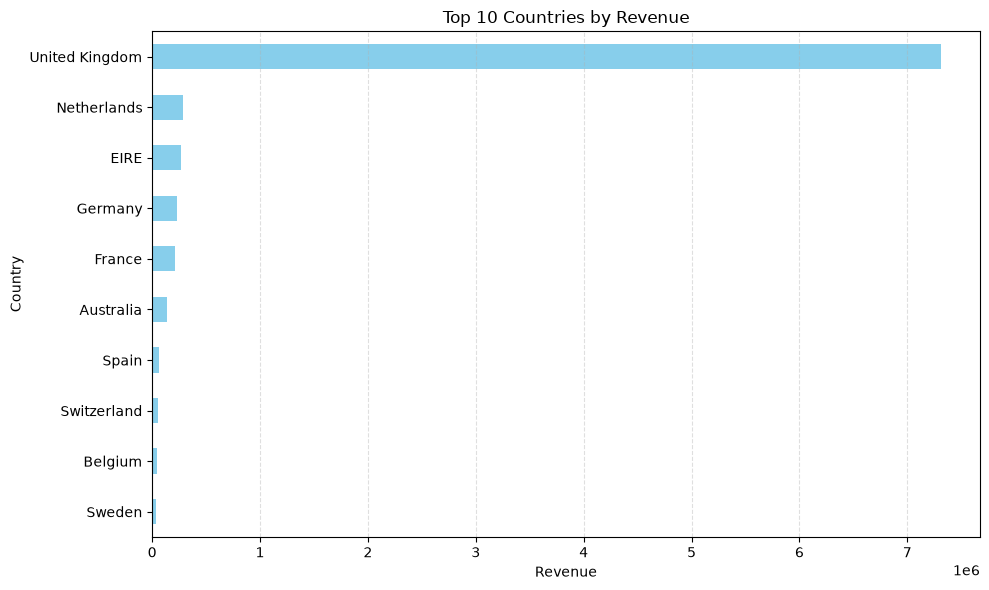

In [16]:

# Plot the top 10 countries by revenue

plt.figure(figsize=(10,6))

top_countries.sort_values().plot(
    kind='barh',
    color='skyblue'
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")

plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()

plt.show()

### Business Insight

- The United Kingdom contributes the highest revenue among all countries.
- Revenue is concentrated in a small number of countries.
- Expanding operations in high-performing countries and improving sales in lower-performing markets could increase overall business revenue.

### Top Countries by Revenue (Excluding United Kingdom)

Since the United Kingdom contributes the majority of the total revenue, it is excluded to better compare the remaining countries.

In [17]:
# Exclude United Kingdom

top_countries_without_uk = (
    df[df['Country'] != 'United Kingdom']
    .groupby('Country')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_countries_without_uk

Country
Netherlands    285446.34
EIRE           265545.90
Germany        228867.14
France         209024.05
Australia      138521.31
Spain           61577.11
Switzerland     56443.95
Belgium         41196.34
Sweden          38378.33
Japan           37416.37
Name: TotalPrice, dtype: float64

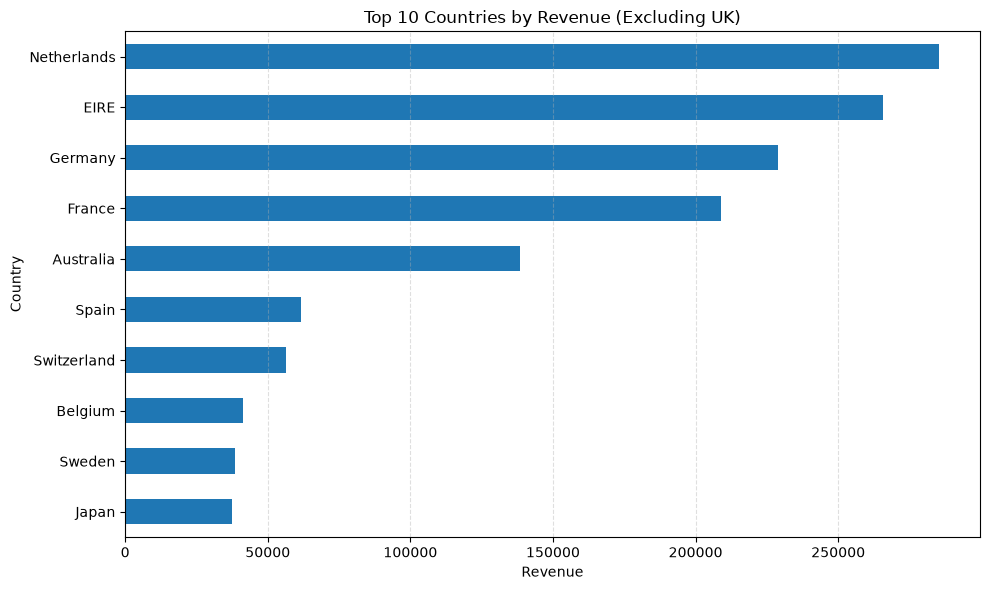

In [18]:
# Plot top countries excluding United Kingdom

plt.figure(figsize=(10,6))

top_countries_without_uk.sort_values().plot(kind='barh')

plt.title("Top 10 Countries by Revenue (Excluding UK)")
plt.xlabel("Revenue")
plt.ylabel("Country")

plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()

plt.show()

### Business Insight

- The United Kingdom dominates the overall revenue, making it difficult to compare other countries.
- After excluding the United Kingdom, the Netherlands, EIRE, Germany, and France emerge as the top revenue-generating countries.
- This visualization provides a clearer comparison of the company's performance across other international markets.

### Monthly Sales Trend

This analysis calculates the total sales revenue for each month to identify seasonal trends and business performance over time.

In [19]:
# Calculate monthly sales

monthly_sales = (
    df.groupby(['InvoiceYear', 'InvoiceMonth'])['TotalPrice']
      .sum()
      .reset_index()
)

monthly_sales

,InvoiceYear,InvoiceMonth,TotalPrice
0,2010,12,572713.890
1,2011,1,569445.040
2,2011,2,447137.350
3,2011,3,595500.760
4,2011,4,469200.361
5,2011,5,678594.560
6,2011,6,661213.690
7,2011,7,600091.011
8,2011,8,645343.900
9,2011,9,952838.382


### Monthly Revenue Trend

This line chart shows how total revenue changes over different months, helping identify sales trends and seasonal patterns.

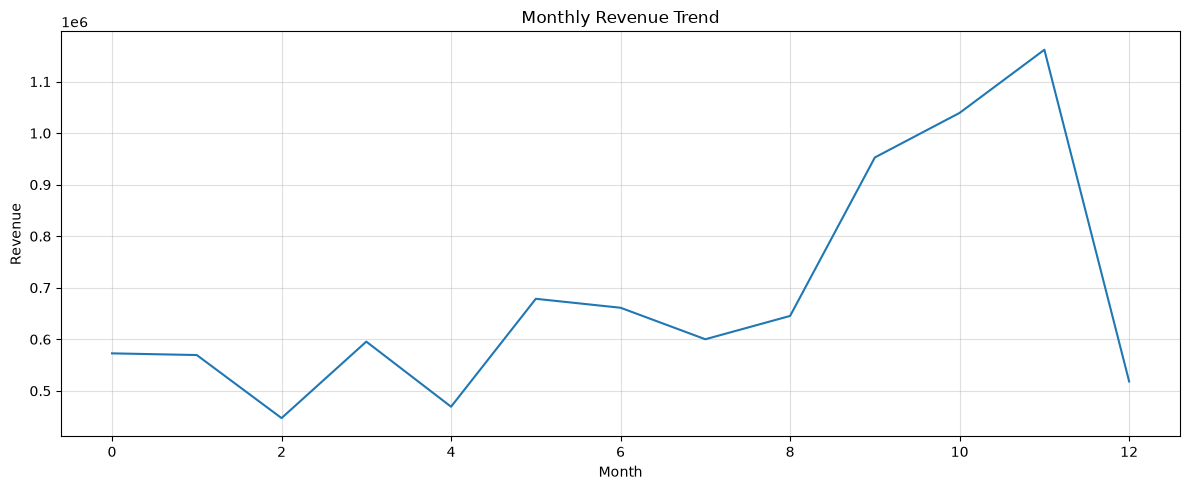

In [20]:
# Plot monthly revenue trend

plt.figure(figsize=(12,5))

plt.plot(monthly_sales['TotalPrice'])

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.grid(alpha=0.4)

plt.tight_layout()

plt.show()

### Business Insight

- Monthly revenue varies throughout the year, indicating changing customer demand.
- Some months generate significantly higher revenue, suggesting seasonal sales patterns.
- Understanding these trends helps businesses plan inventory, promotions, and marketing campaigns more effectively.

### Top 10 Products by Revenue

This analysis identifies the top 10 products that generated the highest total revenue.

In [21]:
# Calculate the top 10 products by revenue

top_products = (
    df.groupby('Description')['TotalPrice']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_products

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142592.95
WHITE HANGING HEART T-LIGHT HOLDER    100448.15
JUMBO BAG RED RETROSPOT                85220.78
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68844.33
ASSORTED COLOUR BIRD ORNAMENT          56580.34
Manual                                 53779.93
RABBIT NIGHT LIGHT                     51346.20
Name: TotalPrice, dtype: float64

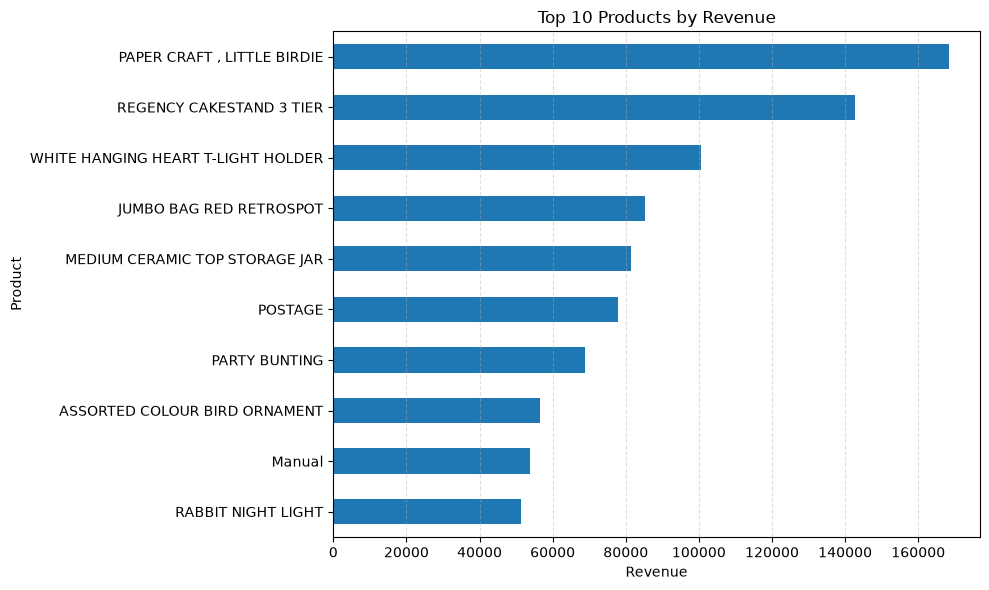

In [22]:
# Plot the top 10 products by revenue

plt.figure(figsize=(10,6))

top_products.sort_values().plot(kind='barh')

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()

plt.show()

### Business Insight

- The top 10 products contribute a significant share of the total revenue.
- These products are consistently high-performing and should be prioritized for inventory and promotional campaigns.
- Focusing on these products can help maximize revenue and improve customer satisfaction.

### Top 10 Customers by Revenue

This analysis identifies the top 10 customers based on their total purchase value.

In [23]:
# Calculate the top 10 customers by revenue

top_customers = (
    df.groupby('CustomerID')['TotalPrice']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_customers

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194550.79
16446.0    168472.50
14911.0    143825.06
12415.0    124914.53
14156.0    117379.63
17511.0     91062.38
16029.0     81024.84
12346.0     77183.60
Name: TotalPrice, dtype: float64

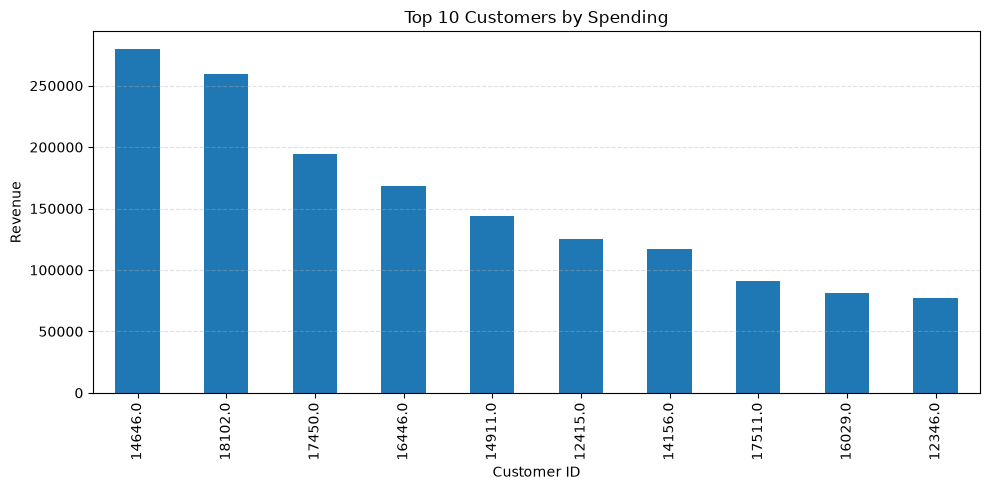

In [24]:
# Plot the top 10 customers by spending

plt.figure(figsize=(10,5))

top_customers.plot(kind='bar')

plt.title("Top 10 Customers by Spending")
plt.xlabel("Customer ID")
plt.ylabel("Revenue")

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()

plt.show()

### Sales by Day of the Week

This analysis calculates the total revenue generated on each day of the week to identify the busiest sales days.

In [25]:
# Calculate total sales by day of the week

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

sales_day = (
    df.groupby('InvoiceDay')['TotalPrice']
      .sum()
      .reindex(day_order)
)

sales_day

InvoiceDay
Monday       1367146.411
Tuesday      1700634.631
Wednesday    1588336.170
Thursday     1976859.070
Friday       1485917.401
Saturday             NaN
Sunday        792514.221
Name: TotalPrice, dtype: float64

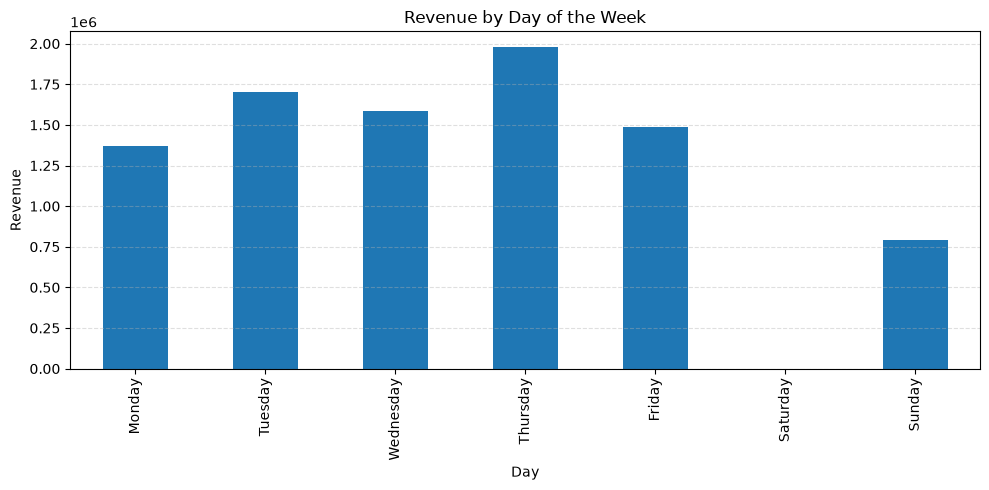

In [26]:
# Plot revenue by day of the week

plt.figure(figsize=(10,5))

sales_day.plot(kind='bar')

plt.title("Revenue by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Revenue")

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()

plt.show()

## RFM Analysis

RFM (Recency, Frequency, Monetary) analysis is used to segment customers based on their purchasing behavior.

In [27]:
# Set the reference date for Recency calculation

snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

snapshot_date

Timestamp('2011-12-10 12:50:00')

### Create the RFM Table

Group the dataset by customer and calculate the three RFM metrics:

- **Recency:** Days since the customer's last purchase.
- **Frequency:** Number of unique purchases made by the customer.
- **Monetary:** Total amount spent by the customer.

In [28]:
# Create the RFM table

rfm = df.groupby('CustomerID').agg({

    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,

    'InvoiceNo': 'nunique',

    'TotalPrice': 'sum'
})

rfm

,InvoiceDate,InvoiceNo,TotalPrice
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
...,...,...,...
18280.0,278,1,180.60
18281.0,181,1,80.82
18282.0,8,2,178.05


### Rename the RFM Columns

Rename the calculated columns to **Recency**, **Frequency**, and **Monetary** for better readability and easier analysis.

In [29]:
# Rename the RFM columns

rfm.columns = ['Recency', 'Frequency', 'Monetary']

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


### Summary Statistics of RFM Metrics

Display descriptive statistics for the Recency, Frequency, and Monetary columns to understand the overall distribution of customer purchasing behavior.

In [30]:
# Display summary statistics for the RFM table

rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


### Assign Recency Score

Divide customers into four equal groups based on their Recency values. Customers who purchased most recently receive the highest score (4), while customers who have not purchased for the longest time receive the lowest score (1).

In [31]:
# Assign Recency Score

rfm['R_Score'] = pd.qcut(
    rfm['Recency'],
    4,
    labels=[4, 3, 2, 1]
)

rfm.head()

,Recency,Frequency,Monetary,R_Score
CustomerID,,,,
12346.0,326,1,77183.60,1
12347.0,2,7,4310.00,4
12348.0,75,4,1797.24,2
12349.0,19,1,1757.55,3
12350.0,310,1,334.40,1


### Assign Frequency Score

Divide customers into four equal groups based on their purchase frequency. Customers with more purchases receive higher scores.

In [32]:
# Assign Frequency Score

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    4,
    labels=[1, 2, 3, 4]
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score
CustomerID,,,,,
12346.0,326,1,77183.60,1,1
12347.0,2,7,4310.00,4,4
12348.0,75,4,1797.24,2,3
12349.0,19,1,1757.55,3,1
12350.0,310,1,334.40,1,1


### Assign Monetary Score

Divide customers into four equal groups based on their total spending. Customers who spend the most receive the highest score (4), while those who spend the least receive the lowest score (1).

In [33]:
# Assign Monetary Score

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'],
    4,
    labels=[1, 2, 3, 4]
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
CustomerID,,,,,,
12346.0,326,1,77183.60,1,1,4
12347.0,2,7,4310.00,4,4,4
12348.0,75,4,1797.24,2,3,4
12349.0,19,1,1757.55,3,1,4
12350.0,310,1,334.40,1,1,2


### Create the Combined RFM Score

Combine the Recency, Frequency, and Monetary scores into a single three-digit RFM score. This score summarizes each customer's purchasing behavior and is used for customer segmentation.

In [34]:
# Create the combined RFM score

rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,77183.60,1,1,4,114
12347.0,2,7,4310.00,4,4,4,444
12348.0,75,4,1797.24,2,3,4,234
12349.0,19,1,1757.55,3,1,4,314
12350.0,310,1,334.40,1,1,2,112


### Define Customer Segments

Create a function to classify customers into different segments based on their RFM scores. This helps identify valuable customers and supports targeted business strategies.

In [35]:
# Define customer segments based on RFM scores

def customer_segment(row):

    if row['RFM_Score'] == '444':
        return 'VIP Customers'

    elif str(row['R_Score']) == '4':
        return 'Loyal Customers'

    elif str(row['F_Score']) == '4':
        return 'Frequent Customers'

    elif str(row['M_Score']) == '4':
        return 'Big Spenders'

    else:
        return 'Regular Customers'

### Apply Customer Segmentation

Apply the customer segmentation function to each customer in the RFM table and create a new **Segment** column.

In [36]:
# Apply customer segmentation

rfm['Segment'] = rfm.apply(customer_segment, axis=1)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
CustomerID,,,,,,,,
12346.0,326,1,77183.60,1,1,4,114,Big Spenders
12347.0,2,7,4310.00,4,4,4,444,VIP Customers
12348.0,75,4,1797.24,2,3,4,234,Big Spenders
12349.0,19,1,1757.55,3,1,4,314,Big Spenders
12350.0,310,1,334.40,1,1,2,112,Regular Customers


### Customer Segment Distribution

Count the number of customers in each segment to understand the distribution of customer groups after RFM segmentation.

In [37]:
# Display the number of customers in each segment

rfm['Segment'].value_counts()

Segment
Regular Customers     2532
Loyal Customers        635
VIP Customers          490
Frequent Customers     476
Big Spenders           205
Name: count, dtype: int64

### Customer Segment Distribution

Visualize the number of customers in each segment using a bar chart to compare the size of different customer groups.

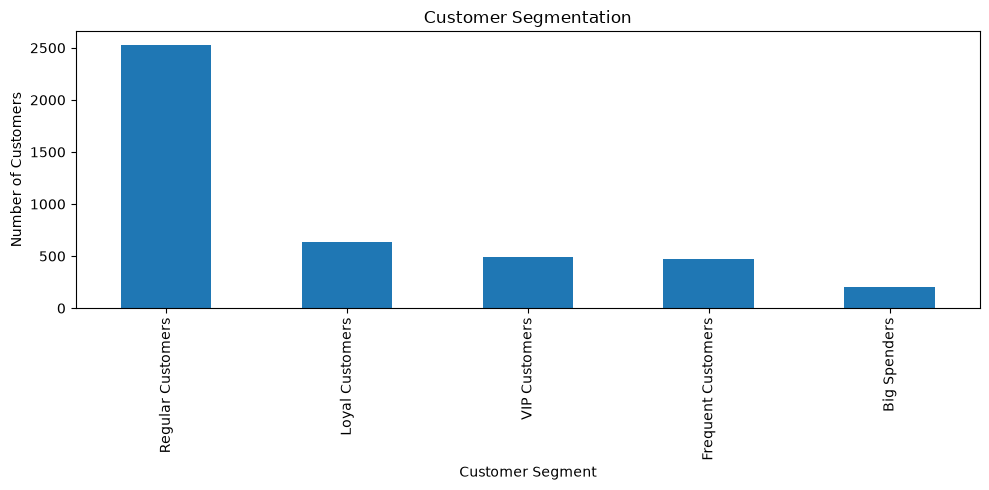

In [38]:
# Plot the distribution of customer segments

rfm['Segment'].value_counts().plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Customer Segmentation')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')

plt.tight_layout()

plt.show()

### Export the RFM Dataset

Save the final RFM dataset with customer scores and segments as a CSV file for further analysis and Power BI visualization.

In [39]:
# Export the final RFM dataset

rfm.to_csv(
    "../Datasets/rfm_analysis_results.csv",
    index=True
)

print("RFM dataset saved successfully!")

RFM dataset saved successfully!


### Export the Cleaned Dataset

Save the cleaned and transformed dataset as a CSV file for further analysis and Power BI dashboard development.

In [40]:
# Export the cleaned dataset

df.to_csv(
    "../Datasets/sales_analysis_dataset.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## Conclusion

This project analyzed customer purchasing behavior using the Online Retail dataset.

Key findings:
- The United Kingdom generated the highest revenue.
- A small number of products contributed a large share of sales.
- Customer purchasing behavior was segmented using RFM analysis.
- The processed datasets were exported for Power BI dashboard development.

In [42]:
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

# ---------------------------------
# MySQL Connection
# ---------------------------------
connection_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password="qweasdzxc123/@",   # Your MySQL password
    host="localhost",
    port=3306,
    database="customer_sales_insights"
)

engine = create_engine(connection_url)

# ---------------------------------
# Export cleaned dataset to MySQL
# ---------------------------------
df.to_sql(
    name="sales_analysis_dataset",
    con=engine,
    if_exists="replace",
    index=False
)

print("✅ Cleaned dataset exported to MySQL.")

# ---------------------------------
# Export RFM dataset to MySQL
# ---------------------------------
rfm.to_sql(
    name="rfm_analysis_results",
    con=engine,
    if_exists="replace",
    index=True
)

print("✅ RFM dataset exported to MySQL.")
print("🎉 Both tables exported successfully!")

✅ Cleaned dataset exported to MySQL.
✅ RFM dataset exported to MySQL.
🎉 Both tables exported successfully!
